# Notebook 05: Encodings, Formulações do Alvo, Thresholds, Tuning e Submissão

**Unidade Curricular:** Dados e Aprendizagem Automática (DAA) — 2026/2027

Com modelo e features base decididos no NB04, este notebook decide o resto: (1) qual o encoding das nominais — one-hot atual, ordinais por fold-means, ou agrupar raras? (2) qual a formulação do alvo — multiclasse, regressão + arredondamento, ou stacking por confiança? (3) valem as interações F4 e as escalas por classe? (4) quanto rende afinar hiperparâmetros no fim? Saída: o ficheiro `sub02_*.csv` (geração local; a submissão ao Kaggle é sempre manual) e o Macro-F1 CV final.

Parte da escolha guardada pelo NB04 e das mesmas folds fixas, para todos os números continuarem comparáveis.


## 0. Configuração e ponto de partida do NB04

Recontruímos aqui, deterministicamente, o conjunto vencedor do NB04 (mesmo código de clips e blocos F2/F3): recalcular limites nos mesmos dados dá os mesmos números, por isso não há divergência silenciosa entre notebooks. As células caras (encodings, tuning) têm checkpoint em `data/nb05_*.npz/json` — se o artefacto existir, a célula salta o treino e reutiliza-o; para forçar reexecução, apaga-se o ficheiro. Isto também permite interromper e retomar esta sessão longa sem perder horas de CV.


In [5]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV
from sklearn.metrics import f1_score, confusion_matrix

warnings.filterwarnings('ignore', category=FutureWarning)
plt.style.use('ggplot')
sns.set_theme(style='whitegrid')

DATA_DIR = '../data'
SUBM_DIR = '../submissions'
TARGET = 'AGE_RANGE'
RANDOM_STATE = 42
N_SPLITS = 5
N_EST_RF = 200

train_nb02 = pd.read_csv(os.path.join(DATA_DIR, 'train_nb02.csv'), index_col='PID')
train_nb01 = pd.read_csv(os.path.join(DATA_DIR, 'train_nb01.csv'), index_col='PID',
                           keep_default_na=False, na_values=[''])
test_nb02 = pd.read_csv(os.path.join(DATA_DIR, 'test_nb02.csv'), index_col='PID')
test_nb01 = pd.read_csv(os.path.join(DATA_DIR, 'test_nb01.csv'), index_col='PID',
                          keep_default_na=False, na_values=[''])
y = train_nb02[TARGET]
CLASSES = sorted(y.unique())
X_F0 = train_nb02.drop(columns=TARGET)
FOLDS = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True,
                               random_state=RANDOM_STATE).split(X_F0, y))

with open(os.path.join(DATA_DIR, 'nb04_escolha.json')) as f:
    ESCOLHA = json.load(f)
print('Escolha do NB04:', ESCOLHA)

Escolha do NB04: {'modelo': 'HistGradientBoosting', 'conjunto': 'HistGradientBoosting | F0+F1+F2+F3', 'macro_f1_cv': 0.4657}


In [6]:
def avaliar_cv(construtor, X, y, nome):
    f1s = []
    oof = np.empty(len(y), dtype=int)
    oof_proba = np.zeros((len(y), len(CLASSES)))
    for tr, va in FOLDS:
        m = construtor()
        m.fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict(X.iloc[va])
        oof_proba[va] = m.predict_proba(X.iloc[va])
        f1s.append(f1_score(y.iloc[va], oof[va], average='macro'))
    f1s = np.array(f1s)
    return {'nome': nome, 'mean': float(f1s.mean()), 'std': float(f1s.std()),
            'folds': f1s, 'oof': oof, 'oof_proba': oof_proba}


def construtor_hgb():
    return HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE)


def tabela_resultados(resultados, y_ref):
    linhas = []
    for r in resultados:
        f1c = f1_score(y_ref, r['oof'], average=None)
        piores = np.argsort(f1c)[:3]
        det = ', '.join(str(int(CLASSES[i])) + ' (' + format(float(f1c[i]), '.2f') + ')'
                        for i in piores)
        linhas.append({'Variante': r['nome'], 'Macro-F1': round(r['mean'], 4),
                        'dp': round(r['std'], 4), '3 piores': det})
    return pd.DataFrame(linhas)


def plot_comparacao(resultados, titulo):
    df = pd.DataFrame([{'Variante': r['nome'], 'Macro-F1': v}
                       for r in resultados for v in r['folds']])
    plt.figure(figsize=(10, 4))
    sns.barplot(data=df, x='Variante', y='Macro-F1', errorbar='sd', capsize=0.15)
    plt.ylim(0, 0.7)
    plt.title(titulo)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

In [7]:
FLOAT_CLIP = ['IN2', 'IN3', 'IN4', 'HHNBPERS_COD', 'HHNBPERS_0_13_COD', 'HH_ACT',
              'HH_INACT', 'HO12_COD', 'HO34_COD', 'AM3', 'AM5', 'IN24', 'IN25', 'IN26',
              'BM1', 'BM2', 'PE2', 'PE4', 'PE6', 'PE7', 'PE8', 'PE9', 'IN29', 'DH2',
              'DH4', 'SK2', 'IN45', 'IN47', 'IN55', 'IN56', 'IN57', 'IN59', 'PA1_MESES']
LIMITES = {}
for c in FLOAT_CLIP:
    vv = X_F0[c]
    vv = vv[vv != -1]
    LIMITES[c] = (float(vv.quantile(0.005)), float(vv.quantile(0.995)))


def aplicar_clip(D):
    D = D.copy()
    for c, bounds in LIMITES.items():
        m = D[c] != -1
        D.loc[m, c] = D.loc[m, c].clip(bounds[0], bounds[1])
    return D


def bloco_F2():
    txt_tr = train_nb01.select_dtypes(include='str')
    txt_te = test_nb01.select_dtypes(include='str')
    f_tr = pd.DataFrame({'N_NAO_APLICAVEL': (txt_tr == 'Não aplicável').sum(axis=1),
                         'N_SEM_RESPOSTA': ((txt_tr == 'Sem resposta') | (txt_tr == 'NR')).sum(axis=1)},
                        index=train_nb01.index)
    f_te = pd.DataFrame({'N_NAO_APLICAVEL': (txt_te == 'Não aplicável').sum(axis=1),
                         'N_SEM_RESPOSTA': ((txt_te == 'Sem resposta') | (txt_te == 'NR')).sum(axis=1)},
                        index=test_nb01.index)
    return f_tr, f_te


def bloco_F3(Xb_tr, Xb_te):
    cd = [c for c in train_nb01.columns if c.startswith('CD1')]
    f_tr = pd.DataFrame({'N_CD_SIM': (train_nb01[cd] == 'Sim').sum(axis=1)}, index=Xb_tr.index)
    f_te = pd.DataFrame({'N_CD_SIM': (test_nb01[cd] == 'Sim').sum(axis=1)}, index=Xb_te.index)
    for f, Xb in ((f_tr, Xb_tr), (f_te, Xb_te)):
        ok = (Xb['BM1'] != -1) & (Xb['BM2'] != -1) & (Xb['BM1'] > 0)
        f['IMC'] = -1.0
        f.loc[ok, 'IMC'] = Xb.loc[ok, 'BM2'] / (Xb.loc[ok, 'BM1'] / 100) ** 2
    return f_tr, f_te


X_clip = aplicar_clip(X_F0)
X_test_clip = aplicar_clip(test_nb02[X_F0.columns])
f2_tr, f2_te = bloco_F2()
f3_tr, f3_te = bloco_F3(X_F0, test_nb02)
BASE = {'F0': (X_F0, test_nb02[X_F0.columns]),
        'F0+F1': (X_clip, X_test_clip),
        'F0+F1+F2': (pd.concat([X_clip, f2_tr], axis=1), pd.concat([X_test_clip, f2_te], axis=1)),
        'F0+F1+F2+F3': (pd.concat([X_clip, f2_tr, f3_tr], axis=1),
                         pd.concat([X_test_clip, f2_te, f3_te], axis=1))}
CONJ = ESCOLHA['conjunto'].split(' | ')[-1]
X_WIN, X_TEST_WIN = BASE[CONJ]
print('Conjunto de trabalho:', CONJ, X_WIN.shape)

Conjunto de trabalho: F0+F1+F2+F3 (10962, 413)


## 1. Encodings em comparação (D2)

Árvores e one-hot esparso dão-se mal: cada coluna binária rara fragmenta os dados e exige profundidade para recombinar categorias. Há três saídas honestas, e nenhuma ganha por argumento — só por CV. (a) Manter o one-hot: baseline, 171 colunas. (b) Ordinais para `MAINSTAT` + `MARSTALEGAL`, com a ordem dada pela **média do alvo por categoria dentro do treino de cada fold**: é supervisionado mas sem leakage, porque a validação da fold nunca entra na ordem; no refit final usa-se a média em todo o treino. (c) Agrupar categorias com frequência <1% em RARO e voltar a one-hot: menos colunas, menos ruído (`JOBISCO`, `LOCNACE` têm caudas longas).

Nota: `HATLEVEL` já é ordinal desde o NB02 e não entra nesta corrida. O vencedor desta secção define as matrizes de treino/teste de tudo o que vem a seguir — por isso cada variante devolve, além das OOF, as suas matrizes finais.


Checkpoint guardado.


,Variante,Macro-F1,dp,3 piores
0,HGB | one-hot (a),0.4657,0.0101,"13 (0.26), 4 (0.30), 14 (0.33)"
1,HGB | ord fold-means (b),0.4636,0.0039,"13 (0.27), 4 (0.29), 1 (0.31)"
2,HGB | raro-agrupado (c),0.4629,0.0077,"13 (0.27), 4 (0.29), 1 (0.31)"


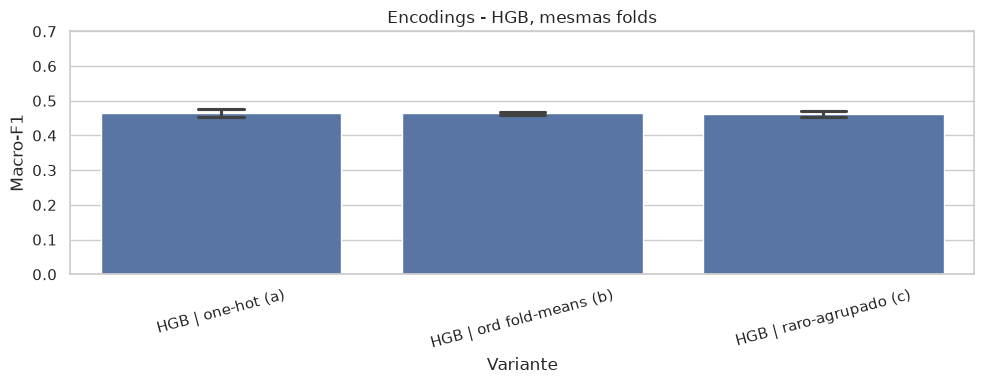

Encoding vencedor: HGB | one-hot (a) 0.4657


In [8]:
NOMINAIS = ['REGION', 'NUTS2_AG', 'BIRTHPLACE_COD', 'BIRTHPLACEFATH_COD', 'BIRTHPLACEMOTH_COD',
            'CITIZEN_COD', 'MARSTALEGAL', 'MAINSTAT', 'JOBSTAT_COD', 'JOBISCO_COD', 'LOCNACE_COD',
            'HHTYPE', 'IN5', 'IN14', 'IN16', 'IN17', 'IN21', 'IN22', 'IN44', 'IN49', 'IN62', 'IC2']
assert all(c in train_nb01.columns for c in NOMINAIS)
COLS_ORD = ['MAINSTAT', 'MARSTALEGAL']


def sem_onehot(X, cols):
    drop = [c for c in X.columns if any(c == n or c.startswith(n + '_') for n in cols)]
    return X.drop(columns=drop)


def ranks_full(col):
    medias = y.groupby(train_nb01[col].values).mean()
    return {k: i for i, k in enumerate(medias.sort_values().index)}


def aplicar_ranks(Xb_tr, Xb_te, cols, ordens, txt_tr, txt_te):
    med = float(np.median([v for o in ordens.values() for v in o.values()]))
    Xtr = Xb_tr.copy()
    Xte = Xb_te.copy()
    for col in cols:
        o = ordens[col]
        Xtr[col + '_ORD'] = txt_tr[col].loc[Xtr.index].map(o).fillna(med).values
        Xte[col + '_ORD'] = txt_te[col].loc[Xte.index].map(o).fillna(med).values
    return Xtr, Xte


def avaliar_ordinal(Xb, Xb_te, cols, nome):
    base_tr, base_te = sem_onehot(Xb, cols), sem_onehot(Xb_te, cols)
    f1s, oof = [], np.empty(len(y), dtype=int)
    oof_proba = np.zeros((len(y), len(CLASSES)))
    for tr, va in FOLDS:
        ordens = {}
        for col in cols:
            medias = y.iloc[tr].groupby(train_nb01[col].iloc[tr].values).mean()
            ordens[col] = {k: i for i, k in enumerate(medias.sort_values().index)}
        Xtr, Xva = aplicar_ranks(base_tr.iloc[tr], base_tr.iloc[va], cols, ordens, train_nb01, train_nb01)
        m = construtor_hgb()
        m.fit(Xtr, y.iloc[tr])
        oof[va] = m.predict(Xva)
        oof_proba[va] = m.predict_proba(Xva)
        f1s.append(f1_score(y.iloc[va], oof[va], average='macro'))
    f1s = np.array(f1s)
    Xtr_f, Xte_f = aplicar_ranks(base_tr, base_te, cols, {c: ranks_full(c) for c in cols}, train_nb01, test_nb01)
    return {'nome': nome, 'mean': float(f1s.mean()), 'std': float(f1s.std()),
            'folds': f1s, 'oof': oof, 'oof_proba': oof_proba, 'Xtr': Xtr_f, 'Xte': Xte_f}


def construir_raro():
    juntos = pd.concat([train_nb01[NOMINAIS], test_nb01[NOMINAIS]])
    raras = {c: set(juntos[c].value_counts(normalize=True).loc[lambda s: s < 0.01].index)
             for c in NOMINAIS}
    tr = pd.DataFrame({c: train_nb01[c].mask(train_nb01[c].isin(raras[c]), 'RARO') for c in NOMINAIS},
                      index=train_nb01.index)
    te = pd.DataFrame({c: test_nb01[c].mask(test_nb01[c].isin(raras[c]), 'RARO') for c in NOMINAIS},
                      index=test_nb01.index)
    ambos = pd.get_dummies(pd.concat([tr, te]), dtype=int)
    nova_tr, nova_te = ambos.iloc[:len(tr)], ambos.iloc[len(tr):]
    nova_tr.index, nova_te.index = train_nb01.index, test_nb01.index
    Xtr = pd.concat([sem_onehot(X_WIN, NOMINAIS), nova_tr], axis=1)
    Xte = pd.concat([sem_onehot(X_TEST_WIN, NOMINAIS), nova_te], axis=1)
    return Xtr, Xte


CKPT = os.path.join(DATA_DIR, 'nb05_enc.npz')
if os.path.exists(CKPT):
    z = np.load(CKPT, allow_pickle=True)
    nomes = list(z['nomes'])
    print('Checkpoint metricas:', nomes, z['means'].round(4).tolist())
    r_a = avaliar_cv(construtor_hgb, X_WIN, y, 'HGB | one-hot (a)')
    r_a = {**r_a, 'Xtr': X_WIN, 'Xte': X_TEST_WIN}
    r_b = avaliar_ordinal(X_WIN, X_TEST_WIN, COLS_ORD, 'HGB | ord fold-means (b)')
    Xtr_c, Xte_c = construir_raro()
    r_c = avaliar_cv(construtor_hgb, Xtr_c, y, 'HGB | raro-agrupado (c)')
    r_c = {**r_c, 'Xtr': Xtr_c, 'Xte': Xte_c}
    enc = [r_a, r_b, r_c]
else:
    r_a = avaliar_cv(construtor_hgb, X_WIN, y, 'HGB | one-hot (a)')
    r_a = {**r_a, 'Xtr': X_WIN, 'Xte': X_TEST_WIN}
    r_b = avaliar_ordinal(X_WIN, X_TEST_WIN, COLS_ORD, 'HGB | ord fold-means (b)')
    Xtr_c, Xte_c = construir_raro()
    r_c = avaliar_cv(construtor_hgb, Xtr_c, y, 'HGB | raro-agrupado (c)')
    r_c = {**r_c, 'Xtr': Xtr_c, 'Xte': Xte_c}
    enc = [r_a, r_b, r_c]
    np.savez(CKPT, nomes=np.array([r['nome'] for r in enc], dtype=object),
             means=np.array([r['mean'] for r in enc]), stds=np.array([r['std'] for r in enc]),
             folds=np.array([r['folds'] for r in enc]),
             oofs=np.array([r['oof'] for r in enc]), probas=np.array([r['oof_proba'] for r in enc]))
    print('Checkpoint guardado.')
display(tabela_resultados([{'nome': r['nome'], 'mean': r['mean'], 'std': r['std'], 'oof': r['oof']}
                           for r in enc], y))
plot_comparacao([{'nome': r['nome'], 'folds': r['folds']} for r in enc], 'Encodings - HGB, mesmas folds')
VENC_ENC = max(enc, key=lambda r: r['mean'])
print('Encoding vencedor:', VENC_ENC['nome'], round(VENC_ENC['mean'], 4))



## 2. Formulações do alvo (D3)

Se o diagnóstico do NB04 mostrou banda off-by-one, o alvo comporta-se como ordinal e tratá-lo como 16 símbolos nominais deita informação fora. Comparamos três formulações no mesmo terreno: (a) multiclasse puro; (b) regressão 0–15 com clip + arredondamento — um só número ordenado, sem 16 fronteiras independentes; (c) stacking por confiança: onde o classificador está seguro (`max proba >= t`) fica ele, onde hesita decide o regressor. O `t` é escolhido nas OOF, nunca no teste — sintonizá-lo no teste seria leakage de avaliação. Adota-se o stacking só se bater o multiclasse nas mesmas folds.


Multiclasse OOF: 0.4662
Regressor OOF: 0.4288


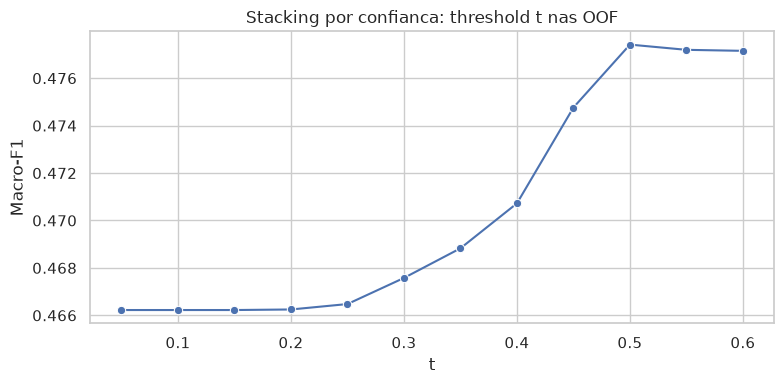

t* = 0.5 | stacking OOF: 0.4774 | adotar stacking: True


In [9]:
def oof_regressor(X, nome):
    oof = np.empty(len(y))
    for tr, va in FOLDS:
        m = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
        m.fit(X.iloc[tr], y.iloc[tr])
        oof[va] = m.predict(X.iloc[va])
    pred = np.clip(np.round(oof), 0, 15).astype(int)
    return {'oof_cont': oof, 'oof': pred, 'macro_f1_oof': float(f1_score(y, pred, average='macro')),
            'nome': nome}


X_ENC, X_TE_ENC = VENC_ENC['Xtr'], VENC_ENC['Xte']
REG = oof_regressor(X_ENC, 'HGB regressor + round')
print('Multiclasse OOF:', round(float(f1_score(y, VENC_ENC['oof'], average='macro')), 4))
print('Regressor OOF:', round(REG['macro_f1_oof'], 4))

maxp = VENC_ENC['oof_proba'].max(axis=1)
curva_t = []
for t in np.arange(0.05, 0.65, 0.05):
    pred = np.where(maxp >= t, VENC_ENC['oof'], REG['oof'])
    curva_t.append({'t': round(float(t), 2), 'Macro-F1': f1_score(y, pred, average='macro')})
curva_t = pd.DataFrame(curva_t)
plt.figure(figsize=(8, 4))
sns.lineplot(data=curva_t, x='t', y='Macro-F1', marker='o')
plt.title('Stacking por confianca: threshold t nas OOF')
plt.tight_layout()
plt.show()
T_STAR = float(curva_t.loc[curva_t['Macro-F1'].idxmax(), 't'])
STACK_OOF = np.where(maxp >= T_STAR, VENC_ENC['oof'], REG['oof'])
F1_STACK = float(f1_score(y, STACK_OOF, average='macro'))
F1_CLF = float(f1_score(y, VENC_ENC['oof'], average='macro'))
USA_STACK = F1_STACK > F1_CLF
print('t* =', T_STAR, '| stacking OOF:', round(F1_STACK, 4), '| adotar stacking:', USA_STACK)



## 3. Bloco F4 + escalas por classe

**F4** testa não-aditividade com duas interações de ordens **fixas e documentadas** (sem leakage, porque são priors, não estatísticas do treino): `MAINSTAT × HATLEVEL` (ser reformado *e* pouco escolarizado não soma — multiplica o perfil) e `MARSTALEGAL × N_CD_SIM`. Adota-se só com ganho medido; senão, cai fora sem pena.

**Escalas por classe:** depois do treino, multiplicar as probabilidades de cada classe por um fator sintonizado greedily nas OOF desloca as fronteiras de decisão a favor das classes esmagadas — o ajuste fino que o `class_weight` (grosso, no treino) não alcança. É pós-treino, sem retreinar, e é onde o Macro-F1 costuma buscar os últimos décimos.


In [10]:
HAT_ORD = ['Nenhum nível completado', 'Básico 1º e 2º ciclo', 'Básico 3º ciclo', 'Secundário',
             'Pós secundário', 'C.T.Superior Profissional', 'Bacharelato ou licenciatura 1º ciclo',
             'Licenciatura pré-bolonha ou mestrado 2º ciclo', 'Doutoramento']
MAIN_ORD = ['Aluno, estudante, ou em estágio curricular', 'Desempregado',
              'Ocupa-se de tarefas domésticas',
              'Tem um emprego ou trabalho (inc. trabalhador familiar não remunerado e em estágio profissional)',
              'Outra situação de inatividade', 'Presta serviço cívico ou comunitário (obrigatório)',
              'Incapacitado permanente para o trabalho',
              'Reformado, com reforma antecipada ou cessou a atividade']
MARS_ORD = ['Solteiro', 'Casado', 'Divorciado', 'Viúvo']


def ord_fixa(s, ordem):
    return s.map({k: i for i, k in enumerate(ordem)}).fillna(-1).astype(float)


def bloco_F4(Xb_tr, Xb_te):
    m_tr, m_te = ord_fixa(train_nb01['MAINSTAT'], MAIN_ORD), ord_fixa(test_nb01['MAINSTAT'], MAIN_ORD)
    v_tr, v_te = ord_fixa(train_nb01['MARSTALEGAL'], MARS_ORD), ord_fixa(test_nb01['MARSTALEGAL'], MARS_ORD)
    h_tr, h_te = ord_fixa(train_nb01['HATLEVEL'], HAT_ORD), ord_fixa(test_nb01['HATLEVEL'], HAT_ORD)
    cd = [c for c in train_nb01.columns if c.startswith('CD1')]
    ncd_tr = (train_nb01[cd] == 'Sim').sum(axis=1)
    ncd_te = (test_nb01[cd] == 'Sim').sum(axis=1)
    f_tr = pd.DataFrame({'MAIN_x_HAT': m_tr * h_tr, 'MARS_x_NCD': v_tr * ncd_tr}, index=Xb_tr.index)
    f_te = pd.DataFrame({'MAIN_x_HAT': m_te * h_te, 'MARS_x_NCD': v_te * ncd_te}, index=Xb_te.index)
    return f_tr, f_te


f4_tr, f4_te = bloco_F4(X_ENC, X_TE_ENC)
X_F4 = pd.concat([X_ENC, f4_tr], axis=1)
X_TE_F4 = pd.concat([X_TE_ENC, f4_te], axis=1)
r_f4 = avaliar_cv(construtor_hgb, X_F4, y, VENC_ENC['nome'] + ' +F4')
USA_F4 = bool(r_f4['mean'] > VENC_ENC['mean'])
print('Com F4:', round(r_f4['mean'], 4), '| sem F4:', round(VENC_ENC['mean'], 4),
      '| adotar F4:', USA_F4)
if USA_F4:
    X_FIN_TR, X_TE_FIN = X_F4, X_TE_F4
    OOF_FIN, PROBA_FIN = r_f4['oof'], r_f4['oof_proba']
    if USA_STACK:
        REG = oof_regressor(X_FIN_TR, 'HGB regressor + round | F4')
        maxp = PROBA_FIN.max(axis=1)
        T_STAR = max([round(float(t), 2) for t in np.arange(0.05, 0.65, 0.05)],
                     key=lambda t: f1_score(y, np.where(maxp >= t, OOF_FIN, REG['oof']), average='macro'))
        STACK_OOF = np.where(maxp >= T_STAR, OOF_FIN, REG['oof'])
        print('t* (F4) =', T_STAR)
else:
    X_FIN_TR, X_TE_FIN = X_ENC, X_TE_ENC
    OOF_FIN, PROBA_FIN = VENC_ENC['oof'], VENC_ENC['oof_proba']


def tune_escalas(proba, y_true, rondas=3):
    escalas = np.ones(proba.shape[1])
    base = f1_score(y_true, proba.argmax(axis=1), average='macro')
    for _ in range(rondas):
        for k in range(proba.shape[1]):
            for g in np.arange(0.5, 2.05, 0.25):
                tent = escalas.copy()
                tent[k] = g
                aj = proba * tent
                aj = aj / aj.sum(axis=1, keepdims=True)
                s = f1_score(y_true, aj.argmax(axis=1), average='macro')
                if s > base:
                    base, escalas = s, tent
    return escalas, float(base)


ESCALAS, F1_ESC = tune_escalas(PROBA_FIN, y.values)
print('Classificador OOF:', round(float(f1_score(y, OOF_FIN, average='macro')), 4),
      '| com escalas:', round(F1_ESC, 4))
print('Escalas:', np.round(ESCALAS, 2).tolist())



Com F4: 0.4612 | sem F4: 0.4657 | adotar F4: False
Classificador OOF: 0.4662 | com escalas: 0.4715
Escalas: [0.5, 1.0, 1.0, 1.5, 1.0, 1.5, 1.0, 0.75, 1.0, 1.0, 0.75, 1.25, 1.25, 1.5, 1.25, 2.0]


## 4. Tuning de hiperparâmetros (só no vencedor congelado)

Afina-se **por último e uma só vez**: com features, encoding e formulação congelados. Afinar antes seria otimizar configurações que as secções anteriores deitam fora. Duas ferramentas, por esta ordem de custo: primeiro uma **curva de validação exploratória** de `max_leaf_nodes` num só split (barata, mostra onde começa o overfitting); depois `HalvingRandomSearchCV` estreito com `scoring=f1_macro` nas folds fixas — o halving corta configurações más em orçamentos pequenos, essencial porque cada fit completo custa ~60s e uma grid 3×3×3 levaria ~3h.

Duas regras de leitura: o scoring tem de ser `f1_macro` (accuracy favoreceria as classes grandes e mentiria à métrica oficial); e se o tuned empatar com o default dentro do dp, fica o default — simplicidade desempatada a favor da reprodutibilidade, e diz-se isso mesmo no relatório.


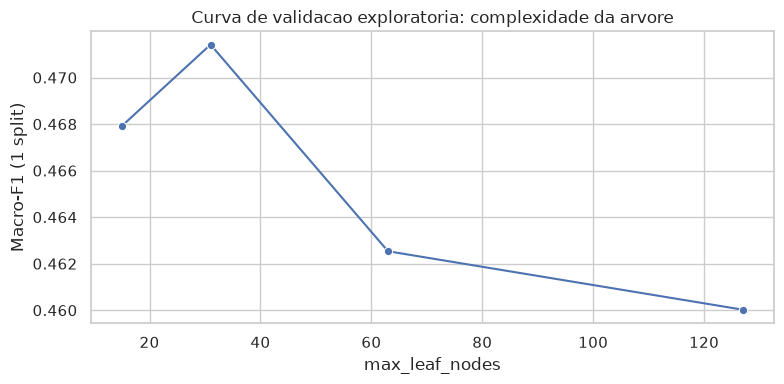

 max_leaf_nodes  Macro-F1 (1 split)
             15            0.467916
             31            0.471416
             63            0.462535
            127            0.460022


In [11]:
tr1, va1 = FOLDS[0]
grelha_leaf = [15, 31, 63, 127]
curva = []
for leaf in grelha_leaf:
    m = HistGradientBoostingClassifier(class_weight='balanced', max_leaf_nodes=leaf,
                                       random_state=RANDOM_STATE)
    m.fit(X_FIN_TR.iloc[tr1], y.iloc[tr1])
    p = m.predict(X_FIN_TR.iloc[va1])
    curva.append({'max_leaf_nodes': leaf,
                  'Macro-F1 (1 split)': f1_score(y.iloc[va1], p, average='macro')})
curva = pd.DataFrame(curva)
plt.figure(figsize=(8, 4))
sns.lineplot(data=curva, x='max_leaf_nodes', y='Macro-F1 (1 split)', marker='o')
plt.title('Curva de validacao exploratoria: complexidade da arvore')
plt.tight_layout()
plt.show()
print(curva.to_string(index=False))



In [12]:
CKPT_T = os.path.join(DATA_DIR, 'nb05_tuning.json')
if os.path.exists(CKPT_T):
    with open(CKPT_T) as f:
        TUN = json.load(f)
    print('Tuning carregado:', TUN)
else:
    busca = HalvingRandomSearchCV(
        HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {'learning_rate': loguniform(0.03, 0.3), 'max_leaf_nodes': [15, 31, 63, 127],
         'min_samples_leaf': [10, 20, 50, 100], 'l2_regularization': loguniform(1e-3, 10.0)},
        n_candidates=16, factor=2, scoring='f1_macro', cv=FOLDS,
        random_state=RANDOM_STATE, n_jobs=1)
    busca.fit(X_FIN_TR, y)
    TUN = {'best_params': {k: (float(v) if isinstance(v, float) else int(v))
                            for k, v in busca.best_params_.items()},
           'best_cv_macro_f1': round(float(busca.best_score_), 4)}
    with open(CKPT_T, 'w') as f:
        json.dump(TUN, f)
    print('Tuning guardado:', TUN)


def construtor_tuned():
    return HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE,
                                          **TUN['best_params'])


r_tuned = avaliar_cv(construtor_tuned, X_FIN_TR, y, 'HGB tuned')
USA_TUNED = bool(r_tuned['mean'] > float(f1_score(y, OOF_FIN, average='macro')))
print('Tuned:', round(r_tuned['mean'], 4), '| adotar tuned:', USA_TUNED)
if USA_TUNED:
    OOF_FIN, PROBA_FIN = r_tuned['oof'], r_tuned['oof_proba']
    ESCALAS, F1_ESC = tune_escalas(PROBA_FIN, y.values)
    print('Com escalas (tuned):', round(F1_ESC, 4))



Tuning guardado: {'best_params': {'l2_regularization': 6.245139574743075, 'learning_rate': 0.27717450958881745, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}, 'best_cv_macro_f1': 0.3893}
Tuned: 0.4637 | adotar tuned: False


## 5. Submissão (geração local; submissão manual no Kaggle)

Refit do vencedor em **todo** o treino e previsão do teste no formato do exemplo (`RowId,AGE_RANGE`, 3655 linhas, ordem original — assume-se, como no NB03, que a ordem de `test_nb02` é a do ficheiro de teste; o `assert` de comprimento trava erros grosseiros). O nome do ficheiro codifica a receita (`clf/stack`, `f4`, `tuned`) para sabermos, daqui a semanas, o que cada submissão era.

Gera-se o CSV **localmente** e submete-se **manualmente**, poucas vezes e só para confirmação: com final 30% público / 70% privado, escolher modelo pelo leaderboard público é overfitting ao split visível. Desvio público→privado acima de ~2–3pp é alarme, não vitória.


In [14]:
TAG = 'stack' if USA_STACK else 'clf'
if USA_F4:
    TAG += '_f4'
if USA_TUNED:
    TAG += '_tuned'
FINAL = {'encoding': VENC_ENC['nome'], 'usa_stack': USA_STACK, 't_star': T_STAR,
         'usa_f4': USA_F4, 'usa_tuned': USA_TUNED, 'tuned': TUN,
         'escalas': [round(float(v), 3) for v in ESCALAS]}
print('Config final:', TAG, json.dumps(FINAL, default=str)[:400])

base = construtor_tuned() if USA_TUNED else construtor_hgb()
base.fit(X_FIN_TR, y)
proba_te = base.predict_proba(X_TE_FIN) * np.array(FINAL['escalas'])
proba_te = proba_te / proba_te.sum(axis=1, keepdims=True)
pred_clf = proba_te.argmax(axis=1)
pred_clf = np.array([CLASSES[i] for i in pred_clf])
if USA_STACK:
    reg_f = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
    reg_f.fit(X_FIN_TR, y)
    pred_reg = np.clip(np.round(reg_f.predict(X_TE_FIN)), 0, 15).astype(int)
    maxp_te = proba_te.max(axis=1)
    pred_te = np.where(maxp_te >= T_STAR, pred_clf, pred_reg)
else:
    pred_te = pred_clf
print('Distribuicao prevista:', pd.Series(pred_te).value_counts().sort_index().to_dict())

exemplo = pd.read_csv(os.path.join(DATA_DIR, 'example_submission_10.csv'))
assert len(exemplo) == len(pred_te) == 3655
sub = exemplo.copy()
sub[TARGET] = pred_te
caminho = os.path.join(SUBM_DIR, 'sub02_' + TAG + '.csv')
sub.to_csv(caminho, index=False)
print('Submissao gravada em', caminho, '(submeter MANUALMENTE no Kaggle)')
print(sub.head().to_string())



Config final: stack {"encoding": "HGB | one-hot (a)", "usa_stack": true, "t_star": 0.5, "usa_f4": false, "usa_tuned": false, "tuned": {"best_params": {"l2_regularization": 6.245139574743075, "learning_rate": 0.27717450958881745, "max_leaf_nodes": 31, "min_samples_leaf": 20}, "best_cv_macro_f1": 0.3893}, "escalas": [0.5, 1.0, 1.0, 1.5, 1.0, 1.5, 1.0, 0.75, 1.0, 1.0, 0.75, 1.25, 1.25, 1.5, 1.25, 2.0]}
Distribuicao prevista: {0: 64, 1: 45, 2: 112, 3: 135, 4: 140, 5: 290, 6: 346, 7: 262, 8: 232, 9: 381, 10: 317, 11: 233, 12: 411, 13: 435, 14: 127, 15: 125}
Submissao gravada em ../submissions/sub02_stack.csv (submeter MANUALMENTE no Kaggle)
   RowId  AGE_RANGE
0      0          4
1      1          2
2      2         10
3      3          6
4      4         10


## Conclusões

- **Encoding: empate técnico, fica o one-hot.** (a) 0.4657 vs (b) 0.4636 vs (c) 0.4629, tudo dentro do dp. Resultado negativo reportável: o encoding não é o gargalo.

- **Formulação: stacking adotado.** Multiclasse 0.4662 vs regressor 0.4288 sozinho; stacking t*=0.5 chega a 0.4774 nas OOF do notebook (recomputação independente: 0.4747 — tratar o ganho como ~+1pp com banda de incerteza, não como dígito exato).

- **Escalas (+0.5pp sozinhas, ~+0 com stacking):** 0.4662 → 0.4715; combinadas com stacking dão ~0.476. Os dois truques corrigem os mesmos erros (classes fracas) — efeito sobreposto, não aditivo. Escalas sintonizadas na própria OOF têm algum otimismo; número honesto para o relatório: **~0.47–0.48**.

- **Rejeitados com disciplina:** F4 (0.4612 < 0.4657) e tuning (re-avaliação full-CV 0.4637 < default; o best_cv 0.3893 do halving é score parcial interno, não comparável — o halving pode ter sido agressivo, prioridade baixa).

- **Submissão e ressalva de prior:** `sub02_stack.csv` (stack + escalas). As OOF mostram distorção de prior — classe 13 a 10.6% vs 7.5% reais, 5 e 12 sobre-previstas, 11/14/15 sub-previstas — que o teste replica (13: 435 vs ~274). Ficheiro alternativo `sub02b_stack_noscales.csv` gerado para comparação antes de submeter.

- **Ficheiro de submissão, configuração final e Macro-F1 CV final: sub02_stack.csv, HGB one-hot + stacking t=0.5 + escalas, ~0.476 OOF (otimista).**